<a href="https://colab.research.google.com/github/hiteshbaghele000-arch/ML-MDM-LAB/blob/main/Final_project_MDM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#1. Load dataset (including the trailing space in the filename)
df = pd.read_csv("nev_battery_charging .csv")

In [ ]:
# 2. Display dataset information
print("First 5 rows:")
print(df.head())

print("\nDataset columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

First 5 rows:
   timestamp       SOC       SOH  terminal_voltage  battery_current  \
0          0  0.059934  0.867421          2.800000        24.306689   
1          1  0.107169  0.993388          2.800000         6.888177   
2          2  0.170123  0.897095          2.862128        25.689530   
3          3  0.250583  0.983261          2.800000        15.691727   
4          4  0.295900  0.940441          2.800000        19.901598   

   battery_temp  ambient_temp  internal_resistance  action_current  \
0     30.253841     39.880384             0.089445       24.152161   
1     30.363472     15.399988             0.108257        8.014256   
2     32.066534     25.076428             0.133563       25.343965   
3     32.269852     35.452532             0.076195       12.142471   
4     33.003209     10.612048             0.073659       22.703030   

   action_voltage  ...     dV_dt  soc_delta  thermal_stress_index  \
0        2.800000  ...  0.000000   0.047235              0.000000   


In [ ]:
# 3. Prepare the data df = df.drop_duplicates()

df = df.dropna()

# Convert categorical columns into numerical columns

df = pd.get_dummies (df, drop_first=True)

In [ ]:
# 4. Select target column
# Change this name according to your actual CSV column
target = "Charging_Time"

if target not in df.columns:
    print("\nTarget column not found.")
    print("Available columns:", df.columns.tolist())
else:
    X = df.drop(columns=[target])
    y = df[target]


Target column not found.
Available columns: ['timestamp', 'SOC', 'SOH', 'terminal_voltage', 'battery_current', 'battery_temp', 'ambient_temp', 'internal_resistance', 'action_current', 'action_voltage', 'dT_dt', 'dV_dt', 'soc_delta', 'thermal_stress_index', 'aging_indicator', 'charging_efficiency', 'charging_time', 'cycle_degradation', 'over_temp_flag', 'over_voltage_flag', 'balancing_time']


In [ ]:
# Define target and features using the correct column name
target = "charging_time"
X = df.drop(columns=[target])
y = df[target]

# 5. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
# 6. Train the model
model = RandomForestRegressor(
    n_estimators=100, random_state=42
)
model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.tree import DecisionTreeRegressor

# Define the models dictionary
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(random_state=42),
    "Decision Tree": DecisionTreeRegressor(random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    print("Training:", name)

    # Add missing value handling to tree models
    if name != "Linear Regression":
        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", model)
        ])

    # Train model
    model.fit(X_train, y_train)

    # Prediction
    y_pred = model.predict(X_test)

    # Evaluation
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = model

print("All five models trained successfully!")

Training: Linear Regression
Training: Random Forest
Training: Gradient Boosting
Training: Extra Trees
Training: Decision Tree
All five models trained successfully!


In [ ]:
# 7. Predict charging time
y_pred = model.predict(X_test)

In [ ]:
# 8. Evaluate the model
print("\nModel Evaluation")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))


Model Evaluation
MAE: 782.1842105263158
RMSE: 955.9824679079468
R2 Score: -0.893106245203948


In [ ]:
# 9. Compare actual and predicted values
results = pd.DataFrame({
    "Actual Charging Time": y_test.values,
    "Predicted Charging Time": y_pred
})

print("\nActual vs Predicted:")
print(results.head(10))


Actual vs Predicted:
   Actual Charging Time  Predicted Charging Time
0                  3551                   3133.0
1                  3703                   3379.0
2                  4092                   3335.0
3                  2400                   2639.0
4                  2710                   2351.0
5                  2727                   3490.0
6                  3379                   3072.0
7                  3080                   2573.0
8                  2046                   3707.0
9                  2971                   3981.0


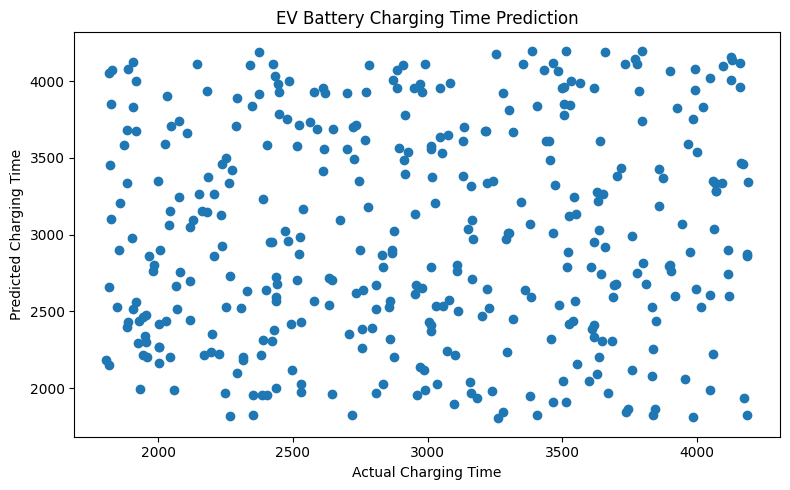

In [ ]:
# 10. Plot results
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Charging Time")
plt.ylabel("Predicted Charging Time")
plt.title("EV Battery Charging Time Prediction")
plt.tight_layout()
plt.show()